# NB08: Orchestration and Data Public API Walkthrough

This notebook covers the orchestration and data layers. You will learn:

1. GraphIR validation, compilation, and the topological execution order
2. The SSOT variable catalog behind typed port specifications
3. Single-variable CF metadata checks and the I/O health check
4. The public API surface of `relic.orchestration` and `relic.data`

**Prerequisites:** NB01-NB07.

**Theory Reference:** `docs/source/coertheory.md`, Section 3.6 (Theorem 3.6.1,
DAG compilation and deterministic topological order; Proposition 3.6.2, port
connection checks).

## Architecture Anchor

This notebook is aligned with `docs\source\architecture_overview.md` and the relevant theory/API pages under `docs\source`.
All computations below are intended to use actual RELIC functors, the actual simulator or orchestration layer, and real validation pathways rather than notebook-defined pseudo-process equations.


### Orchestration and Data Pipeline

The RELIC orchestration layer compiles a `GraphIR` into an execution plan:
`compile_graph` validates the graph and orders its nodes by a deterministic
topological sort, so the plan respects the DAG constraint (**Theorem 3.6.1**):

$$
\forall\; (u, v) \in E(\mathcal{G}): \quad \text{exec}(u) < \text{exec}(v)
$$

**Dependency levels** group the nodes that have no edge between them:

$$
G_k = \{v \in V : \text{depth}(v) = k\}
$$

The compiled plan is one ordered list of steps. In the simulator,
`DependencyGraph.get_parallel_groups()` reports these levels as candidates for
concurrent execution, but the Functors are still executed sequentially.

The data layer checks the CF metadata of one variable at a time (`standard_name`
and `units` against the bundled CF Standard Name Table v94); it does not certify
dataset-level CF conformance.

## Setup and Imports

Import the orchestration layer components and data pipeline utilities.

In [1]:
from __future__ import annotations

# Use only the standard library so notebook execution stays self-contained on Windows.
import asyncio
if hasattr(asyncio, "WindowsSelectorEventLoopPolicy"):
    asyncio.set_event_loop_policy(asyncio.WindowsSelectorEventLoopPolicy())

# --- Environment Guard (prevent OpenMP duplicate lib crash) ---
import os, sys
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import json
import sys
import warnings
from pathlib import Path

DEFAULT_PROJECT_ROOT = Path(os.environ.get("RELIC_PROJECT_ROOT", Path.cwd())).resolve()

def locate_project_root() -> Path:
    candidates = [
        Path.cwd(),
        Path.cwd().parent,
        Path.cwd().parent.parent,
        DEFAULT_PROJECT_ROOT,
    ]
    for candidate in candidates:
        candidate = candidate.resolve()
        if (candidate / "relic").exists() and (candidate / "tutorial").exists():
            return candidate
    raise RuntimeError("Project root not found from current working directory")

PROJECT_ROOT = locate_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from relic.orchestration import (
    GraphIR,
    NodeRegistry,
    SSOTCatalog,
    compile_graph,
    load_graph,
    save_graph,
    validate_graph,
)
from relic.orchestration.ssot_catalog import SSOTEntry
from relic.data import check_cf_variable_metadata, get_standard_units, standardize_variable_name
from relic.data.io import io_healthcheck

OUTPUT_DIR = PROJECT_ROOT / "tutorial" / "primary" / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SUMMARY_PATH = OUTPUT_DIR / "08_orchestration_data_summary.json"
GRAPH_PATH = OUTPUT_DIR / "08_orchestration_demo_graph.json"

print("[OK] project_root =", PROJECT_ROOT)
print("[OK] summary_path =", SUMMARY_PATH)
print("[OK] graph_path =", GRAPH_PATH)


[OK] project_root = <RELIC_ROOT>
[OK] summary_path = tutorial\primary\output\08_orchestration_data_summary.json
[OK] graph_path = tutorial\primary\output\08_orchestration_demo_graph.json


## Graph Compilation and the SSOT Catalog

Build a two-node `GraphIR`, save and reload it, register node definitions whose
typed ports take their metadata from the SSOT catalog, then validate and compile
the graph. The same cell queries the SSOT catalog: each entry is keyed by its
variable name, and one CF identity (`standard_name` plus `cell_methods`) belongs to
one variable. A contradicting second declaration of a name, or a CF identity
claimed by a second variable, raises `ValueError` while the catalog is built, so a
loaded catalog carries no conflict list.
This `strict=False` example only validates and compiles placeholder nodes;
it does not instantiate or advance scientific Functors. GraphExecutor
requires a strict compile-run witness and explicit `n_steps` and `dt`;
this placeholder plan is not presented as a runnable scientific graph.

In [2]:
# References:
# - relic/orchestration/graph_ir.py.
# - relic/orchestration/graph_io.py.
# - relic/orchestration/validator.py.
# - relic/orchestration/compiler.py.
# - relic/orchestration/ssot_catalog.py.
# Mathematical expression:
# - G = (V, E), where V is the node set and E is the directed link set.
# - A valid compile path requires that every edge respects the port contracts.
# - SSOT identity: one entry per variable name; one variable per CF identity
#   (standard_name, cell_methods).
# Parameter meanings:
# - node_count: number of graph nodes.
# - link_count: number of graph links.
# - step_count: number of execution steps in the compiled plan.
# - ssot_sample_units: catalog units of the sample variables.
# - ssot_cf_identity_lookup: variable that holds a (standard_name, cell_methods) identity.
# Units: variable units are read from the SSOT catalog; this cell sets none.
# Domain/constraints: catalog loading raises ValueError on a contradicting declaration
#   or on a CF identity claimed by two variables; there is no conflict list.
# Sign convention: not applicable to graph and metadata checks.

graph = GraphIR.from_dict(
    {
        "schema_version": "1.0.0",
        "nodes": {
            "source": {
                "class_type": "external.source",
                "outputs": ["soil_temperature"],
            },
            "sink": {
                "class_type": "external.sink",
                "inputs": {
                    "soil_temperature": {
                        "link": ["source", "soil_temperature"],
                    }
                },
            },
        },
        "metadata": {"tutorial": "orchestration_data_demo"},
    }
)

save_graph(graph, GRAPH_PATH)
loaded_graph = load_graph(GRAPH_PATH)
ssot_catalog = SSOTCatalog.from_parameter_manager()
registry = NodeRegistry(ssot_catalog)
registry.register_definition(
    "external.source",
    registry.build_from_node_spec("external.source", [], ["soil_temperature"]),
)
registry.register_definition(
    "external.sink",
    registry.build_from_node_spec("external.sink", ["soil_temperature"], []),
)
validation_report = validate_graph(loaded_graph, registry, strict=False)
execution_plan = compile_graph(loaded_graph, registry, strict=False)

sample_names = ["soil_temperature", "gross_primary_productivity", "air_temperature"]
ssot_hits = {name: ssot_catalog.get(name) is not None for name in sample_names}
ssot_sample_units = {name: ssot_catalog.get(name).units for name in sample_names}

# CF identity = (standard_name, cell_methods): a request without cell_methods selects
# the entry that declares none, a qualified request selects the qualified entry.
ssot_cf_identity_lookup = {
    "air_temperature": ssot_catalog.get_by_standard_name("air_temperature").name,
    "air_temperature | time: maximum": ssot_catalog.get_by_standard_name(
        "air_temperature", cell_methods="time: maximum"
    ).name,
}

# The catalog keeps no conflict list: a second variable that claims an existing CF
# identity raises ValueError while entries are added (shown on a scratch catalog).
scratch_catalog = SSOTCatalog()
scratch_catalog.add_entry(SSOTEntry(name="demo_temperature_a", standard_name="air_temperature", units="K"))
try:
    scratch_catalog.add_entry(SSOTEntry(name="demo_temperature_b", standard_name="air_temperature", units="K"))
except ValueError as exc:
    duplicate_identity_error = str(exc)
else:
    raise AssertionError("A second variable with the same CF identity must be rejected")

orchestration_summary = {
    "ssot_sample_hits": ssot_hits,
    "ssot_sample_units": ssot_sample_units,
    "ssot_cf_identity_lookup": ssot_cf_identity_lookup,
    "ssot_duplicate_cf_identity_error": duplicate_identity_error,
    "graph_path": str(GRAPH_PATH),
    "graph_node_count": len(loaded_graph.nodes),
    "graph_link_count": len(loaded_graph.links),
    "graph_validate_error_count": len(validation_report.errors),
    "graph_validate_warning_count": len(validation_report.warnings),
    "graph_compile_step_count": len(execution_plan.steps),
}

assert orchestration_summary["graph_node_count"] == 2
assert orchestration_summary["graph_link_count"] == 1
assert orchestration_summary["graph_validate_error_count"] == 0
assert orchestration_summary["graph_compile_step_count"] == 2
assert orchestration_summary["ssot_sample_hits"]["soil_temperature"] is True
assert orchestration_summary["ssot_cf_identity_lookup"]["air_temperature"] == "air_temperature"

orchestration_summary

{'ssot_sample_hits': {'soil_temperature': True,
  'gross_primary_productivity': True,
  'air_temperature': True},
 'ssot_sample_units': {'soil_temperature': 'K',
  'gross_primary_productivity': 'kg C m-2 s-1',
  'air_temperature': 'K'},
 'ssot_cf_identity_lookup': {'air_temperature': 'air_temperature',
  'air_temperature | time: maximum': 'air_temperature_max'},
 'ssot_duplicate_cf_identity_error': "Variables 'demo_temperature_a' and 'demo_temperature_b' both declare standard_name 'air_temperature' with no qualifier; one CF identity has one variable",
 'graph_path': './workspace',
 'graph_node_count': 2,
 'graph_link_count': 1,
 'graph_validate_error_count': 0,
 'graph_validate_warning_count': 0,
 'graph_compile_step_count': 2}

## CF Variable Metadata and I/O Health

`standardize_variable_name` and `get_standard_units` resolve an exact entry (or a
declared alias) of the bundled CF Standard Name Table v94 and its canonical units;
`check_cf_variable_metadata` validates the `standard_name`/`units` subset of one
variable. `io_healthcheck()` runs `IOHealthChecker.run_full_check()` (dependencies,
formats, compression, performance, CF metadata subset, integration) and returns a
report with one result per check.

In [3]:
# References:
# - relic/data/__init__.py.
# - relic/data/standards/cf_conventions.py.
# - relic/data/io/healthcheck.py.
# Mathematical expression:
# - compliance_pass = 1 if metadata satisfies CF rules else 0.
# Parameter meanings:
# - standard_name: canonical CF variable name.
# - standard_units: canonical CF units for the selected variable.
# - overall_status: summarized I/O health status.
# - io_check_status: status of each check of IOHealthChecker.run_full_check().
# Units: temperature uses the official CF canonical unit K.
# Domain/constraints: standard_name must be an exact CF v94 entry or declared alias.
# Sign convention: not applicable to metadata membership validation.

cf_standard_name_temperature = standardize_variable_name("air_temperature")
cf_standard_units_temperature = get_standard_units(cf_standard_name_temperature)
cf_validation = check_cf_variable_metadata(
    {
        "standard_name": cf_standard_name_temperature,
        "units": cf_standard_units_temperature,
    }
)
cf_compliant = cf_validation.is_valid
cf_issues = list(cf_validation.issues)

with warnings.catch_warnings(record=True) as caught_io_warnings:
    warnings.simplefilter("always", UserWarning)
    io_status = io_healthcheck()

io_warning_messages = sorted({str(item.message) for item in caught_io_warnings})

data_summary = {
    "cf_standard_name_temperature": cf_standard_name_temperature,
    "cf_standard_units_temperature": cf_standard_units_temperature,
    "cf_compliant": bool(cf_compliant),
    "cf_issue_count": len(cf_issues),
    "io_health_status": io_status.overall_status.value,
    "io_check_count": len(io_status.results),
    "io_check_status": {name: result.status.value for name, result in io_status.results.items()},
    "io_warning_count": len(io_warning_messages),
    "io_warning_messages": io_warning_messages[:3],
}

assert data_summary["cf_standard_name_temperature"] == "air_temperature"
assert data_summary["cf_standard_units_temperature"] == "K"
assert data_summary["cf_compliant"] is True
assert data_summary["io_health_status"] != ""

data_summary

{'cf_standard_name_temperature': 'air_temperature',
 'cf_standard_units_temperature': 'K',
 'cf_compliant': True,
 'cf_issue_count': 0,
 'io_health_status': 'healthy',
 'io_check_count': 6,
 'io_check_status': {'dependencies': 'healthy',
  'formats': 'healthy',
  'compression': 'healthy',
  'performance': 'healthy',
  'cf_metadata_subset': 'healthy',
  'integration': 'healthy'},
 'io_warning_count': 0,
 'io_warning_messages': []}

In [4]:
summary = {
    **orchestration_summary,
    **data_summary,
}

SUMMARY_PATH.write_text(json.dumps(summary, indent=2, ensure_ascii=True), encoding="utf-8")

print("[OK] wrote", SUMMARY_PATH)
print("[OK] wrote", GRAPH_PATH)
print("[OK] graph_validate_error_count =", summary["graph_validate_error_count"])
print("[OK] graph_compile_step_count =", summary["graph_compile_step_count"])
print("[OK] io_health_status =", summary["io_health_status"])
print("[OK] cf_standard_name_temperature =", summary["cf_standard_name_temperature"])

summary

[OK] wrote tutorial\primary\output\08_orchestration_data_summary.json
[OK] wrote tutorial\primary\output\08_orchestration_demo_graph.json
[OK] graph_validate_error_count = 0
[OK] graph_compile_step_count = 2
[OK] io_health_status = healthy
[OK] cf_standard_name_temperature = air_temperature


{'ssot_sample_hits': {'soil_temperature': True,
  'gross_primary_productivity': True,
  'air_temperature': True},
 'ssot_sample_units': {'soil_temperature': 'K',
  'gross_primary_productivity': 'kg C m-2 s-1',
  'air_temperature': 'K'},
 'ssot_cf_identity_lookup': {'air_temperature': 'air_temperature',
  'air_temperature | time: maximum': 'air_temperature_max'},
 'ssot_duplicate_cf_identity_error': "Variables 'demo_temperature_a' and 'demo_temperature_b' both declare standard_name 'air_temperature' with no qualifier; one CF identity has one variable",
 'graph_path': './workspace',
 'graph_node_count': 2,
 'graph_link_count': 1,
 'graph_validate_error_count': 0,
 'graph_validate_warning_count': 0,
 'graph_compile_step_count': 2,
 'cf_standard_name_temperature': 'air_temperature',
 'cf_standard_units_temperature': 'K',
 'cf_compliant': True,
 'cf_issue_count': 0,
 'io_health_status': 'healthy',
 'io_check_count': 6,
 'io_check_status': {'dependencies': 'healthy',
  'formats': 'healthy',


## Visualize Dependency Graph & Data Layer Status

Render the dependency DAG $\mathcal{G} = (V, E)$ and summarize
the orchestration/data layer health metrics.


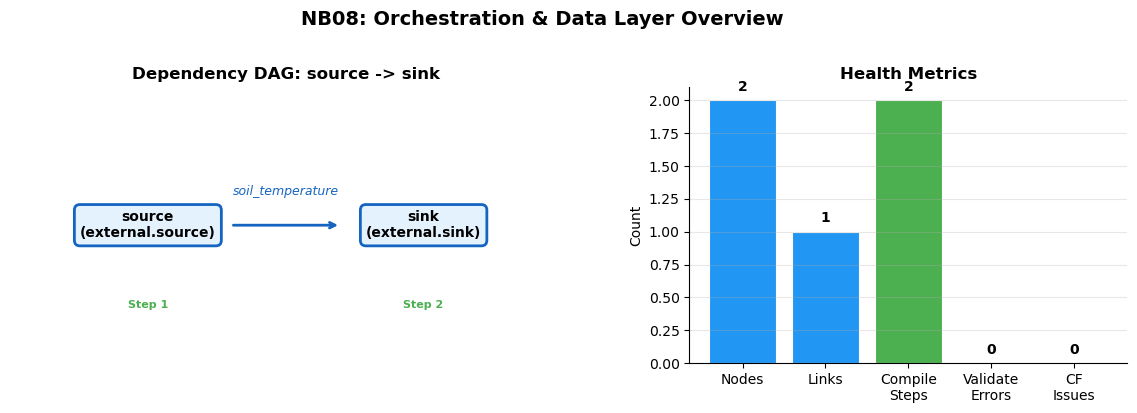

In [5]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# References:
#   relic/orchestration/graph_ir.py: GraphIR data structure
#   relic/orchestration/compiler.py: topological scheduling
# Mathematical expression:
#   G = (V, E) with topological order sigma: V -> {1,...,|V|}
#   (u,v) in E => sigma(u) < sigma(v)
# Parameter meanings:
#   graph_node_count: |V| = number of graph nodes (external.source, external.sink)
#   graph_link_count: |E| = number of graph links
#   graph_compile_step_count: length of compiled execution plan

fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={'width_ratios': [1.5, 1]})

# Panel 1: Dependency Graph (manual layout)
ax = axes[0]
ax.set_xlim(-0.5, 3.5)
ax.set_ylim(-0.5, 1.5)
ax.set_aspect('equal')
ax.axis('off')
ax.set_title('Dependency DAG: source -> sink', fontweight='bold', fontsize=12)

# Draw nodes
node_style = dict(boxstyle='round,pad=0.4', facecolor='#E3F2FD', edgecolor='#1565C0', linewidth=2)
ax.text(0.5, 0.5, 'source\n(external.source)', ha='center', va='center',
        fontsize=10, fontweight='bold', bbox=node_style)
ax.text(2.5, 0.5, 'sink\n(external.sink)', ha='center', va='center',
        fontsize=10, fontweight='bold', bbox=node_style)

# Draw edge with arrow
ax.annotate('', xy=(1.9, 0.5), xytext=(1.1, 0.5),
            arrowprops=dict(arrowstyle='->', color='#1565C0', lw=2))
ax.text(1.5, 0.7, 'soil_temperature', ha='center', va='bottom',
        fontsize=9, fontstyle='italic', color='#1565C0')

# Execution order badge
ax.text(0.5, -0.1, 'Step 1', ha='center', fontsize=8, color='#4CAF50', fontweight='bold')
ax.text(2.5, -0.1, 'Step 2', ha='center', fontsize=8, color='#4CAF50', fontweight='bold')

# Panel 2: Health Metrics
ax2 = axes[1]
metric_labels = ['Nodes', 'Links', 'Compile\nSteps', 'Validate\nErrors', 'CF\nIssues']
metric_values = [
    summary['graph_node_count'],
    summary['graph_link_count'],
    summary['graph_compile_step_count'],
    summary['graph_validate_error_count'],
    summary['cf_issue_count'],
]
colors = ['#2196F3', '#2196F3', '#4CAF50', '#f44336', '#f44336']
bars = ax2.bar(metric_labels, metric_values, color=colors, edgecolor='white', linewidth=0.8)
for bar, val in zip(bars, metric_values):
    ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.05,
            str(int(val)), ha='center', va='bottom', fontsize=10, fontweight='bold')
ax2.set_title('Health Metrics', fontweight='bold', fontsize=12)
ax2.set_ylabel('Count')
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(axis='y', alpha=0.3)

fig.suptitle('NB08: Orchestration & Data Layer Overview', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## Summary

This notebook covered the orchestration and data layers:
- GraphIR save/load, validation, and compilation into a topologically ordered plan
- The SSOT variable catalog: one entry per variable name, one variable per CF identity;
  contradicting declarations raise while the catalog loads
- Typed port specifications that `NodeRegistry` builds from SSOT entries
- Single-variable CF metadata checks (CF Standard Name Table v94) and the I/O health check

**Next:** Proceed to **NB09** for optimization, stochastic, and computation APIs.